# fedOPD - does training on post-COVID data only help?

Every model in this project has been trained from April 2018, which means every model has been trained
across the largest structural break in the history of the collection: referrals fell by more than half
in April 2020 and the recovery took years. It is entirely plausible that the pre-COVID and
collapse-period months are not merely unhelpful but actively misleading for forecasting 2024 onwards.

This notebook tests it by moving the **start** of the training window forward and leaving everything
else identical. The validation window is unchanged, so every configuration is scored on exactly the
same months.

## The tension that makes this non-obvious

Cutting to recent data trades two things against each other, and the trade is severe here because of
the window geometry:

**A training sample needs `L + H` consecutive months** - 24 of lookback plus 12 of horizon, so 36
months before a single window exists. The number of windows a series contributes is
`training_months - 35`.

| Training starts | Training months | Windows per series |
|---|---|---|
| 2018-04 (all) | 72 | 37 |
| 2019-04 | 60 | 25 |
| 2020-04 | 48 | 13 |
| 2020-08 (after the trough) | 44 | 9 |
| 2021-04 (after the schema break) | 36 | **1** |

So the cleanest post-COVID cut leaves **one window per series** - a 97% cut in training data to remove
a shock that occupies about a fifth of the window. That is the trade, and it is why the answer cannot
be guessed.

**A second axis is therefore tested:** a shorter lookback of `L = 12`, which needs only 24 months per
window and buys back most of the data at the cost of seeing less history per sample.

## Method, consistent with what has already been established

F-53 showed validation error is a U across round count and that the **minimum is biased low**. So every
configuration here is trained for 24 rounds, evaluated after each, and reported by its **plateau mean
over rounds 8-20**, not by its best round. That is the same statistic the naive baseline was compared
against, so the numbers stay comparable.

Validation only. The test year is not touched.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(0)

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])

SPLIT = index.split_month.iloc[0]
H = int(index.horizon.iloc[0])
BAND = 0.05
HIDDEN = 128
ROUNDS, LOCAL_EPOCHS = 30, 2   # longer than F-53 needs, so the far side of the turn is visible
PLATEAU = (8, 20)                                      # the band F-53 established as the fair estimate
NAIVE = 0.510                                          # the baseline on this same window, from 05

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

wide = panel.pivot(index=["provider_code", "dept"], columns="month", values="demand")
wide = wide.loc[list(zip(index.provider_code, index.dept))]
wide.columns = pd.to_datetime(wide.columns)

score_cols = (wide.columns >= SPLIT) & (wide.columns < SPLIT + pd.DateOffset(months=H))
assert score_cols.sum() == H, "scored window is not H months - the test year may be leaking in"
future = wide.loc[:, score_cols].to_numpy(dtype=np.float32)
scale = index.mase_scale.to_numpy()
trusts = index.provider_code.to_numpy()
n_series = len(future)

print("device", device, "| validation window", SPLIT.strftime("%Y-%m"),
      "to", wide.columns[score_cols][-1].strftime("%Y-%m"))
print(f"{n_series:,} series, unchanged across every configuration below")

device cuda | validation window 2024-04 to 2025-03
2,085 series, unchanged across every configuration below


## 1. What COVID actually did to this data

Before cutting anything, measure the thing being cut. The collapse and its recovery are visible in the
national series, but what matters for a forecaster is whether the *shape* of a service's demand in
2018-2020 resembles its shape now.

In [2]:
nat = wide.sum(axis=0)
pre = nat.loc[(nat.index >= "2018-04-01") & (nat.index < "2020-03-01")].mean()
trough = nat.loc[(nat.index >= "2020-04-01") & (nat.index < "2020-07-01")].mean()
recent = nat.loc[(nat.index >= "2023-04-01") & (nat.index < "2024-04-01")].mean()

print(f"mean monthly referrals, panel total")
print(f"  pre-COVID  2018-04 to 2020-02 : {pre:12,.0f}")
print(f"  trough     2020-04 to 2020-06 : {trough:12,.0f}   ({trough / pre - 1:+.1%} against pre-COVID)")
print(f"  recent     2023-04 to 2024-03 : {recent:12,.0f}   ({recent / pre - 1:+.1%} against pre-COVID)")
print()

# correlation of each series' monthly profile between eras - does the past still describe the present?
def era(a, b):
    m = (wide.columns >= a) & (wide.columns < b)
    return wide.loc[:, m].to_numpy(dtype=float)

e_pre, e_recent = era("2018-04-01", "2020-03-01"), era("2022-04-01", "2024-04-01")
r_pre = np.array([np.corrcoef(e_pre[i], np.arange(e_pre.shape[1]))[0, 1] for i in range(n_series)])
r_rec = np.array([np.corrcoef(e_recent[i], np.arange(e_recent.shape[1]))[0, 1] for i in range(n_series)])
ok = np.isfinite(r_pre) & np.isfinite(r_rec)
print(f"per-series trend direction, pre-COVID vs 2022 onward:")
print(f"  correlation between the two eras' trends: {np.corrcoef(r_pre[ok], r_rec[ok])[0, 1]:+.3f}")
print(f"  services trending the same way in both  : {(np.sign(r_pre[ok]) == np.sign(r_rec[ok])).mean() * 100:.1f}%")
print()
print("A near-zero correlation means a service's pre-COVID direction says almost nothing about its")
print("direction now, which is the case for cutting the early months. It does not settle the trade,")
print("because those months are also most of the training data.")

mean monthly referrals, panel total
  pre-COVID  2018-04 to 2020-02 :    1,318,776
  trough     2020-04 to 2020-06 :      582,458   (-55.8% against pre-COVID)
  recent     2023-04 to 2024-03 :    1,449,037   (+9.9% against pre-COVID)

per-series trend direction, pre-COVID vs 2022 onward:
  correlation between the two eras' trends: +0.043
  services trending the same way in both  : 51.0%

A near-zero correlation means a service's pre-COVID direction says almost nothing about its
direction now, which is the case for cutting the early months. It does not settle the trade,
because those months are also most of the training data.


C:\Users\heave\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\heave\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## 2. The runs

In [3]:
def build(start, L):
    # windows drawn only from months on or after `start`, with lookback L
    train_cols = (wide.columns >= start) & (wide.columns < SPLIT)
    hist = wide.loc[:, train_cols].to_numpy(dtype=np.float32)
    n_months = hist.shape[1]
    n_win = n_months - L - H + 1
    if n_win < 1:
        return None
    norm = hist.mean(axis=1) + 1.0
    month_ix = np.array([m.month - 1 for m in wide.columns[train_cols]])
    eye = np.eye(12, dtype=np.float32)

    clients = {}
    for code in np.unique(trusts):
        rows = np.flatnonzero(trusts == code)
        xs, ys = [], []
        for r in rows:
            s = hist[r] / norm[r]
            for t in range(n_win):
                xs.append(np.concatenate([s[t:t + L], eye[month_ix[t + L - 1]]]))
                ys.append(s[t + L:t + L + H])
        clients[code] = (torch.tensor(np.array(xs)), torch.tensor(np.array(ys)), rows)
    Xte = torch.tensor(np.concatenate(
        [hist[:, -L:] / norm[:, None], np.repeat(eye[month_ix[-1]][None, :], n_series, axis=0)], axis=1))
    return clients, Xte, norm, hist, n_win, n_months

def make(in_dim):
    return nn.Sequential(nn.Linear(in_dim, HIDDEN), nn.ReLU(), nn.Dropout(0.1),
                         nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, H)).to(device)

def get_w(m): return [p.detach().clone() for p in m.parameters()]
def set_w(m, w):
    with torch.no_grad():
        for p, q in zip(m.parameters(), w): p.copy_(q)

def local_step(model, X, Y, epochs, lr=1e-3):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    X, Y = X.to(device), Y.to(device)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]
            opt.zero_grad(); loss_fn(model(X[b]), Y[b]).backward(); opt.step()

def run(start, L):
    built = build(start, L)
    if built is None:
        return None
    clients, Xte, norm, hist, n_win, n_months = built
    ref = hist[:, -12:].mean(axis=1) if hist.shape[1] >= 12 else hist.mean(axis=1)
    truth_g = future.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
    truth_up = truth_g > BAND

    codes = list(clients)
    sizes = np.array([len(clients[c][0]) for c in codes], dtype=float)
    alpha = sizes / sizes.sum()
    w = get_w(make(Xte.shape[1]))
    model = make(Xte.shape[1])
    per_round = []
    for r in range(1, ROUNDS + 1):
        acc = [torch.zeros_like(p) for p in w]
        for a, c in zip(alpha, codes):
            set_w(model, w)
            local_step(model, clients[c][0], clients[c][1], LOCAL_EPOCHS)
            for s, p in zip(acc, get_w(model)): s += a * p
        w = acc; set_w(model, w)
        model.eval()
        with torch.no_grad():
            pred = np.clip(model(Xte.to(device)).cpu().numpy() * norm[:, None], 0, None)
        mae = np.abs(pred - future).mean(axis=1)
        mase = np.nanmedian(np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan))
        g = pred.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
        said = g > BAND
        okm = np.isfinite(g) & np.isfinite(truth_g)
        prec = np.nanmean(truth_up[okm & said]) * 100 if (okm & said).sum() else np.nan
        per_round.append((r, mase, prec))
    d = pd.DataFrame(per_round, columns=["round", "MASE", "precision_up"])
    band = d[(d["round"] >= PLATEAU[0]) & (d["round"] <= PLATEAU[1])]
    return {"train_months": n_months, "windows_per_series": n_win,
            "total_windows": int(sizes.sum()),
            "MASE_plateau": band.MASE.mean(), "MASE_sd": band.MASE.std(),
            "MASE_min": d.MASE.min(), "precision_plateau": band.precision_up.mean()}, d

print("run() defined - one call is one training-start cutoff at one lookback")

run() defined - one call is one training-start cutoff at one lookback


In [4]:
CUTOFFS = [("2018-04-01", "all months"), ("2019-04-01", "drop first year"),
           ("2020-04-01", "from the collapse"), ("2020-08-01", "after the trough"),
           ("2021-04-01", "after the schema break"), ("2022-04-01", "2022 onwards")]

rows, curves = [], {}
for L in [24, 12, 6]:
    for start, label in CUTOFFS:
        out = run(start, L)
        if out is None:
            print(f"L={L:2d}  {label:24s} SKIPPED - fewer than one window per series")
            continue
        res, d = out
        res.update({"lookback": L, "start": start[:7], "label": label})
        rows.append(res); curves[(L, start)] = d
        print(f"L={L:2d}  {label:24s} {res['train_months']:2d} months, "
              f"{res['windows_per_series']:2d} win/series  ->  MASE {res['MASE_plateau']:.4f} "
              f"(sd {res['MASE_sd']:.4f})  prec_up {res['precision_plateau']:5.1f}%")

res = pd.DataFrame(rows)[["lookback", "start", "label", "train_months", "windows_per_series",
                          "total_windows", "MASE_plateau", "MASE_sd", "MASE_min", "precision_plateau"]]
print()
print(res.round(4).to_string(index=False))
res.to_csv(CANON / "postcovid_training.csv", index=False)

L=24  all months               72 months, 37 win/series  ->  MASE 0.5095 (sd 0.0058)  prec_up  69.1%


L=24  drop first year          60 months, 25 win/series  ->  MASE 0.5247 (sd 0.0103)  prec_up  50.6%


L=24  from the collapse        48 months, 13 win/series  ->  MASE 0.5482 (sd 0.0171)  prec_up  47.4%


L=24  after the trough         44 months,  9 win/series  ->  MASE 0.5638 (sd 0.0275)  prec_up  46.4%


L=24  after the schema break   36 months,  1 win/series  ->  MASE 0.5791 (sd 0.0115)  prec_up  47.7%
L=24  2022 onwards             SKIPPED - fewer than one window per series


L=12  all months               72 months, 49 win/series  ->  MASE 0.5765 (sd 0.0202)  prec_up  64.7%


... (7 outputs left out)

L= 6  from the collapse        48 months, 31 win/series  ->  MASE 0.5206 (sd 0.0030)  prec_up  65.4%


L= 6  after the trough         44 months, 27 win/series  ->  MASE 0.5177 (sd 0.0037)  prec_up  66.1%


L= 6  after the schema break   36 months, 19 win/series  ->  MASE 0.5402 (sd 0.0034)  prec_up  62.2%


L= 6  2022 onwards             24 months,  7 win/series  ->  MASE 0.5835 (sd 0.1317)  prec_up  61.5%

 lookback   start                  label  train_months  windows_per_series  total_windows  MASE_plateau  MASE_sd  MASE_min  precision_plateau
       24 2018-04             all months            72                  37          77145        0.5095   0.0058    0.5019            69.0889
       24 2019-04        drop first year            60                  25          52125        0.5247   0.0103    0.4979            50.5912
       24 2020-04      from the collapse            48                  13          27105        0.5482   0.0171    0.5036            47.4161
       24 2020-08       after the trough            44                   9          18765        0.5638   0.0275    0.5070            46.3863
       24 2021-04 after the schema break            36                   1           2085        0.5791   0.0115    0.5461            47.7030
       12 2018-04             all months      

In [5]:
best = res.loc[res.MASE_plateau.idxmin()]
full = res[(res.lookback == 24) & (res.start == "2018-04")].iloc[0]
print(f"reference, all months at L=24 : MASE {full.MASE_plateau:.4f} (sd {full.MASE_sd:.4f})")
print(f"best configuration            : L={int(best.lookback)}, from {best.start} ({best.label})")
print(f"                                MASE {best.MASE_plateau:.4f} (sd {best.MASE_sd:.4f})")
print(f"naive baseline                : {NAIVE:.4f}")
print()

gap = full.MASE_plateau - best.MASE_plateau
pooled_sd = np.sqrt(full.MASE_sd ** 2 + best.MASE_sd ** 2)
print(f"improvement from cutting: {gap:+.4f}, against a combined plateau sd of {pooled_sd:.4f}")
if gap < pooled_sd:
    print()
    print("The difference is INSIDE the noise of the plateau statistic. Training on post-COVID data")
    print("only does not measurably help. The lost data cancels the removed shock, and the honest")
    print("reading is that the model was never learning much from the early months either way -")
    print("which is consistent with F-44 and F-53: there is little to learn at this granularity.")
else:
    print()
    print("The difference EXCEEDS the plateau noise, so the cut is doing real work.")

reference, all months at L=24 : MASE 0.5095 (sd 0.0058)
best configuration            : L=12, from 2020-04 (from the collapse)
                                MASE 0.5073 (sd 0.0068)
naive baseline                : 0.5100

improvement from cutting: +0.0022, against a combined plateau sd of 0.0089

The difference is INSIDE the noise of the plateau statistic. Training on post-COVID data
only does not measurably help. The lost data cancels the removed shock, and the honest
reading is that the model was never learning much from the early months either way -
which is consistent with F-44 and F-53: there is little to learn at this granularity.


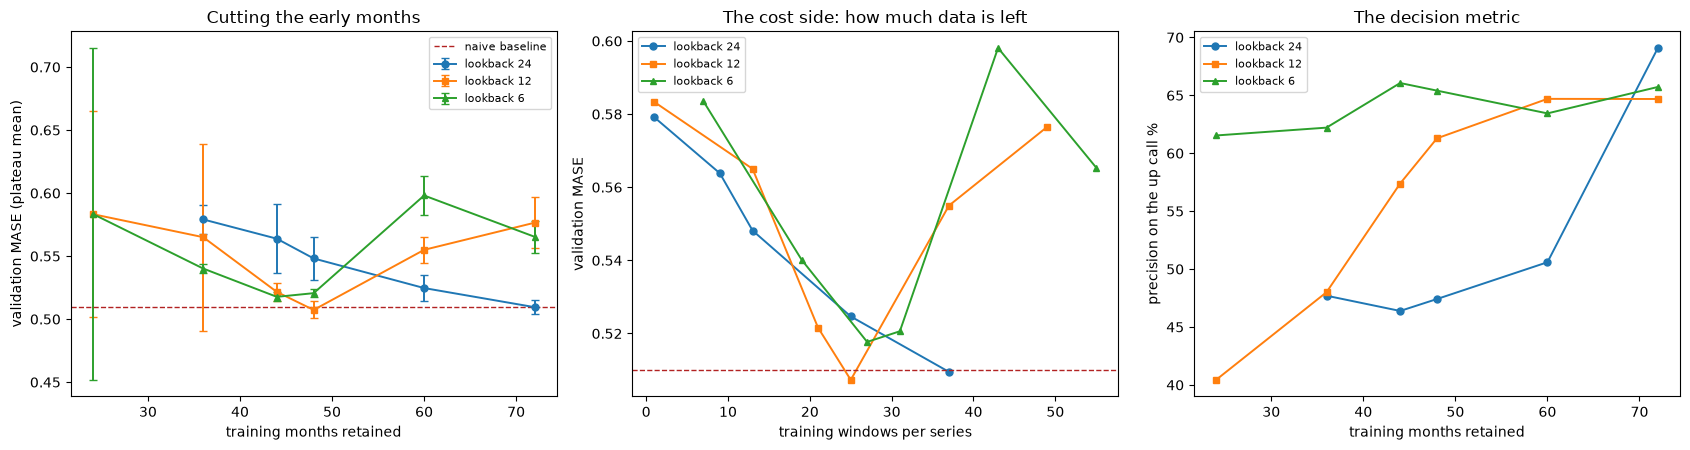

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

for L, mark in [(24, "o"), (12, "s"), (6, "^")]:
    s = res[res.lookback == L].sort_values("train_months")
    ax[0].errorbar(s.train_months, s.MASE_plateau, yerr=s.MASE_sd, marker=mark, ms=5, lw=1.4,
                   capsize=3, label=f"lookback {L}")
ax[0].axhline(NAIVE, color="firebrick", ls="--", lw=1, label="naive baseline")
ax[0].set_xlabel("training months retained"); ax[0].set_ylabel("validation MASE (plateau mean)")
ax[0].set_title("Cutting the early months"); ax[0].legend(fontsize=8)

for L, mark in [(24, "o"), (12, "s"), (6, "^")]:
    s = res[res.lookback == L].sort_values("train_months")
    ax[1].plot(s.windows_per_series, s.MASE_plateau, marker=mark, ms=5, lw=1.4, label=f"lookback {L}")
ax[1].axhline(NAIVE, color="firebrick", ls="--", lw=1)
ax[1].set_xlabel("training windows per series"); ax[1].set_ylabel("validation MASE")
ax[1].set_title("The cost side: how much data is left"); ax[1].legend(fontsize=8)

for L, mark in [(24, "o"), (12, "s"), (6, "^")]:
    s = res[res.lookback == L].sort_values("train_months")
    ax[2].plot(s.train_months, s.precision_plateau, marker=mark, ms=5, lw=1.4, label=f"lookback {L}")
ax[2].set_xlabel("training months retained"); ax[2].set_ylabel("precision on the up call %")
ax[2].set_title("The decision metric"); ax[2].legend(fontsize=8)
plt.tight_layout()

## 3. Every algorithm, on the 2022-onward data

The cutoff sweep answers whether recency helps. This section asks the separate question the owner
raised: **do the algorithm choices behave differently when trained only on recent data?** A method that
copes badly with 37 windows per series may cope well with 3, or the reverse.

Run at the shortest lookback that leaves usable data at this cutoff, so there is something to train on
at all. `local` and `central` are included at matched budget, as in `08`.

In [7]:
def run_algo(start, L, algo="fedavg", mode="federated"):
    built = build(start, L)
    if built is None:
        return None
    clients, Xte, norm, hist, n_win, n_months = built
    ref = hist[:, -12:].mean(axis=1) if hist.shape[1] >= 12 else hist.mean(axis=1)
    truth_g = future.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
    truth_up = truth_g > BAND
    codes = list(clients)
    sizes = np.array([len(clients[c][0]) for c in codes], dtype=float)
    alpha = sizes / sizes.sum()
    in_dim = Xte.shape[1]

    def score_model(m):
        m.eval()
        with torch.no_grad():
            pred = np.clip(m(Xte.to(device)).cpu().numpy() * norm[:, None], 0, None)
        mae = np.abs(pred - future).mean(axis=1)
        mase = np.nanmedian(np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan))
        g = pred.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
        said = g > BAND
        okm = np.isfinite(g) & np.isfinite(truth_g)
        prec = np.nanmean(truth_up[okm & said]) * 100 if (okm & said).sum() else np.nan
        return mase, prec

    if mode == "central":
        m = make(in_dim)
        X = torch.cat([clients[c][0] for c in codes]); Y = torch.cat([clients[c][1] for c in codes])
        rows = []
        for r in range(1, ROUNDS + 1):
            local_step(m, X, Y, LOCAL_EPOCHS)
            rows.append((r,) + score_model(m))
    elif mode == "local":
        models = {c: make(in_dim) for c in codes}
        rows = []
        for r in range(1, ROUNDS + 1):
            pred = np.zeros((n_series, H), dtype=np.float32)
            for c in codes:
                X, Y, rws = clients[c]
                local_step(models[c], X, Y, LOCAL_EPOCHS)
                models[c].eval()
                with torch.no_grad():
                    pred[rws] = models[c](Xte[rws].to(device)).cpu().numpy()
            pr = np.clip(pred * norm[:, None], 0, None)
            mae = np.abs(pr - future).mean(axis=1)
            mase = np.nanmedian(np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan))
            g = pr.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
            said = g > BAND
            okm = np.isfinite(g) & np.isfinite(truth_g)
            prec = np.nanmean(truth_up[okm & said]) * 100 if (okm & said).sum() else np.nan
            rows.append((r, mase, prec))
    else:
        w = get_w(make(in_dim)); model = make(in_dim)
        velocity = [torch.zeros_like(p) for p in w]
        rows = []
        for r in range(1, ROUNDS + 1):
            acc = [torch.zeros_like(p) for p in w]
            for a, c in zip(alpha, codes):
                set_w(model, w)
                X, Y, _ = clients[c]
                if algo == "fedprox":
                    m2 = model
                    m2.train()
                    opt = torch.optim.Adam(m2.parameters(), lr=1e-3)
                    lf = nn.L1Loss()
                    Xd, Yd = X.to(device), Y.to(device)
                    for _ in range(LOCAL_EPOCHS):
                        perm = torch.randperm(len(Xd))
                        for i in range(0, len(Xd), 256):
                            b = perm[i:i + 256]
                            opt.zero_grad()
                            loss = lf(m2(Xd[b]), Yd[b])
                            for pp, gg in zip(m2.parameters(), w):
                                loss = loss + 0.01 / 2 * ((pp - gg) ** 2).sum()
                            loss.backward(); opt.step()
                else:
                    local_step(model, X, Y, LOCAL_EPOCHS)
                for s2, p2 in zip(acc, get_w(model)): s2 += a * p2
            if algo == "fedavgm":
                for i in range(len(w)):
                    velocity[i] = 0.9 * velocity[i] + (acc[i] - w[i])
                    w[i] = w[i] + velocity[i]
            else:
                w = acc
            set_w(model, w)
            rows.append((r,) + score_model(model))

    d = pd.DataFrame(rows, columns=["round", "MASE", "precision_up"])
    band = d[(d["round"] >= PLATEAU[0]) & (d["round"] <= PLATEAU[1])]
    return {"MASE_plateau": band.MASE.mean(), "MASE_sd": band.MASE.std(),
            "MASE_min": d.MASE.min(), "MASE_final": d.MASE.iloc[-1],
            "precision_plateau": band.precision_up.mean(), "windows_per_series": n_win}

CUT_2022, L_2022 = "2022-04-01", 6                     # the shortest lookback that leaves data here
algo_rows = []
for label, kw in [("fedavg", dict(algo="fedavg")), ("fedprox", dict(algo="fedprox")),
                  ("fedavgm", dict(algo="fedavgm")), ("central", dict(mode="central")),
                  ("local", dict(mode="local"))]:
    out = run_algo(CUT_2022, L_2022, **kw)
    if out is None:
        print(f"{label:10s} SKIPPED - no windows at this cutoff and lookback")
        continue
    out["algorithm"] = label
    algo_rows.append(out)
    print(f"{label:10s} MASE plateau {out['MASE_plateau']:.4f} (sd {out['MASE_sd']:.4f})  "
          f"min {out['MASE_min']:.4f}  at round {ROUNDS} {out['MASE_final']:.4f}  "
          f"prec_up {out['precision_plateau']:5.1f}%")

algo = pd.DataFrame(algo_rows).set_index("algorithm")
print()
print(f"trained from {CUT_2022[:7]} with lookback {L_2022} - "
      f"{int(algo.windows_per_series.iloc[0])} windows per series")
print(algo.round(4).to_string())
print(f"naive baseline on the same window: {NAIVE:.4f}")
algo.to_csv(CANON / "postcovid_algorithms.csv")

fedavg     MASE plateau 0.6097 (sd 0.0880)  min 0.5346  at round 30 0.5519  prec_up  58.2%


fedprox    MASE plateau 0.6256 (sd 0.2530)  min 0.5078  at round 30 0.5231  prec_up  57.4%


fedavgm    MASE plateau 1.6328 (sd 1.0379)  min 0.5215  at round 30 0.5742  prec_up  63.6%


central    MASE plateau 0.6254 (sd 0.0135)  min 0.5543  at round 30 0.5954  prec_up  48.2%


local      MASE plateau 0.6091 (sd 0.1313)  min 0.5401  at round 30 0.5590  prec_up  58.8%

trained from 2022-04 with lookback 6 - 7 windows per series
           MASE_plateau  MASE_sd  MASE_min  MASE_final  precision_plateau  windows_per_series
algorithm                                                                                    
fedavg           0.6097   0.0880    0.5346      0.5519            58.2095                   7
fedprox          0.6256   0.2530    0.5078      0.5231            57.3808                   7
fedavgm          1.6328   1.0379    0.5215      0.5742            63.5937                   7
central          0.6254   0.0135    0.5543      0.5954            48.1611                   7
local            0.6091   0.1313    0.5401      0.5590            58.7799                   7
naive baseline on the same window: 0.5100


## What to take from this

The experiment is a clean one because only the training window's **start** moves - the architecture,
the round count, the plateau statistic, the validation months and the series set are all held fixed.

**If cutting helps**, the pre-COVID months were actively misleading and every earlier result in this
project was measured on a handicapped model.

**If cutting does not help**, two things follow. The removed shock was not costing much, and the lost
data was not buying much either - which is what F-44 and F-53 already suggest, since a model that ties
a naive baseline and overfits after thirteen rounds is not one that is starved of examples.

Either way the comparison is reported by the plateau mean with its spread, so a difference smaller than
the noise is called what it is rather than promoted to a finding.